# 🖐️ Sign Language Recognition Using Deep Learning

### Indian Sign Language Recognition using Convolutional Neural Network (CNN)

**Project Type:** Deep Learning Project  
**Model:** Convolutional Neural Network (CNN)  
**Dataset:** ASL Alphabet Dataset  
**Number of Classes:** 29  
**Validation Accuracy:** 81.96%

---

### Objective
To develop a Deep Learning model capable of recognizing different
sign language hand gestures from images.

### Technologies Used
- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully! ✅")

TensorFlow version: 2.21.0
Libraries loaded successfully! ✅


# 1. Dataset Loading


In [2]:
import kagglehub

path = kagglehub.dataset_download("grassknoted/asl-alphabet")

print("Dataset ready! ✅")
print("Path:", path)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset ready! ✅
Path: /kaggle/input/asl-alphabet


In [3]:
train_path = os.path.join(path, "asl_alphabet_train", "asl_alphabet_train")

print("Train folder ready! ✅")
print(os.listdir(train_path)[:10])

Train folder ready! ✅
['N', 'R', 'space', 'B', 'I', 'del', 'F', 'H', 'E', 'U']


# 2. Data Preparation

In [4]:
IMG_SIZE = 64
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

print("Images loaded successfully! ✅")

Found 69600 images belonging to 29 classes.
Found 17400 images belonging to 29 classes.
Images loaded successfully! ✅


# 3. CNN Model Creation

In [5]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(29, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model ready! ✅")

CNN model ready! ✅


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# 4. Model Training

In [6]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 738s 339ms/step - accuracy: 0.6264 - loss: 1.1895 - val_accuracy: 0.7118 - val_loss: 0.9719
Epoch 2/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 660s 304ms/step - accuracy: 0.9038 - loss: 0.2761 - val_accuracy: 0.7910 - val_loss: 0.8155
Epoch 3/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 700s 322ms/step - accuracy: 0.9440 - loss: 0.1576 - val_accuracy: 0.7899 - val_loss: 0.9878
Epoch 4/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 662s 304ms/step - accuracy: 0.9620 - loss: 0.1100 - val_accuracy: 0.8237 - val_loss: 0.8565
Epoch 5/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 692s 318ms/step - accuracy: 0.9728 - loss: 0.0807 - val_accuracy: 0.8196 - val_loss: 0.9731


# 5. Training and Validation Accuracy

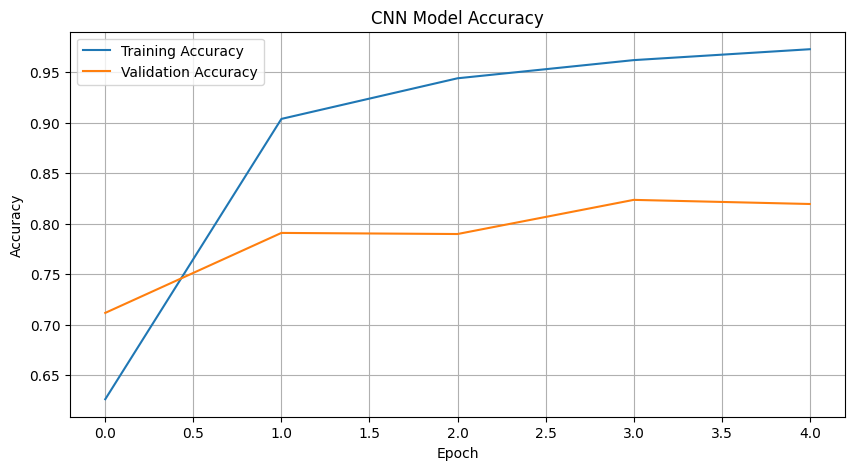

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

# 6. Training and Validation Loss


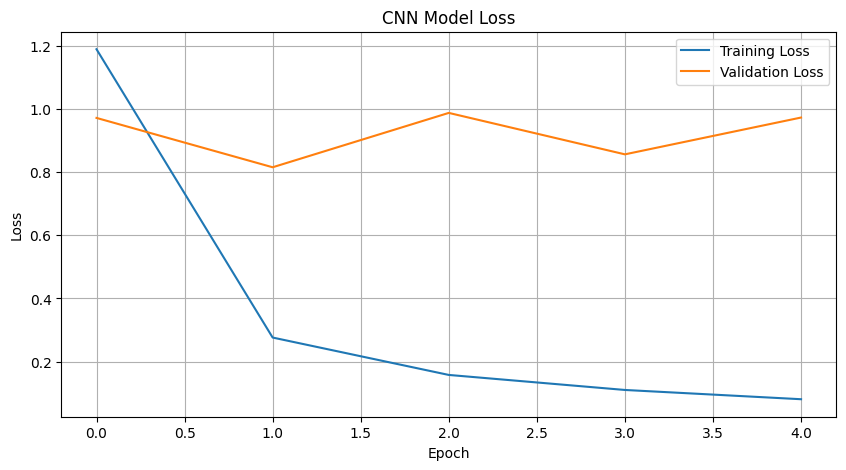

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

# 7. Model Evaluation

In [9]:
loss, accuracy = model.evaluate(val_data)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Validation Loss:", round(loss, 4))

544/544 ━━━━━━━━━━━━━━━━━━━━ 53s 97ms/step - accuracy: 0.8196 - loss: 0.9731
Validation Accuracy: 81.96 %
Validation Loss: 0.9731


# 8. Class Names


In [10]:
class_names = list(train_data.class_indices.keys())

print("Total Classes:", len(class_names))
print("Classes:", class_names)

Total Classes: 29
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


# 9. Sample Prediction


Actual Sign: K
Predicted Sign: K
Confidence: 100.0 %


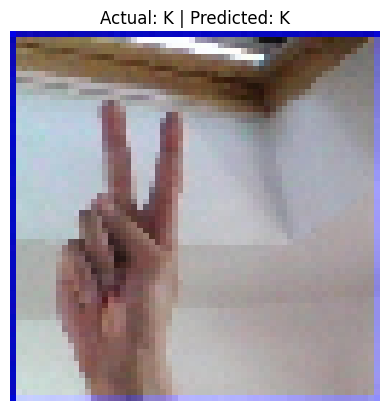

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Get one image from validation data
images, labels = next(val_data)

# Take first image
sample_image = images[0]
true_label = np.argmax(labels[0])

# Predict
prediction = model.predict(np.expand_dims(sample_image, axis=0), verbose=0)
predicted_label = np.argmax(prediction[0])

print("Actual Sign:", class_names[true_label])
print("Predicted Sign:", class_names[predicted_label])
print("Confidence:", round(np.max(prediction[0]) * 100, 2), "%")

# Show image
plt.imshow(sample_image)
plt.title(
    f"Actual: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_label]}"
)
plt.axis("off")
plt.show()

# 10. Model Saving

In [12]:
model.save("Sign_Language_Recognition_CNN.keras")

print("Model saved successfully! ✅")

Model saved successfully! ✅


# 11. Confusion Matrix

544/544 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step


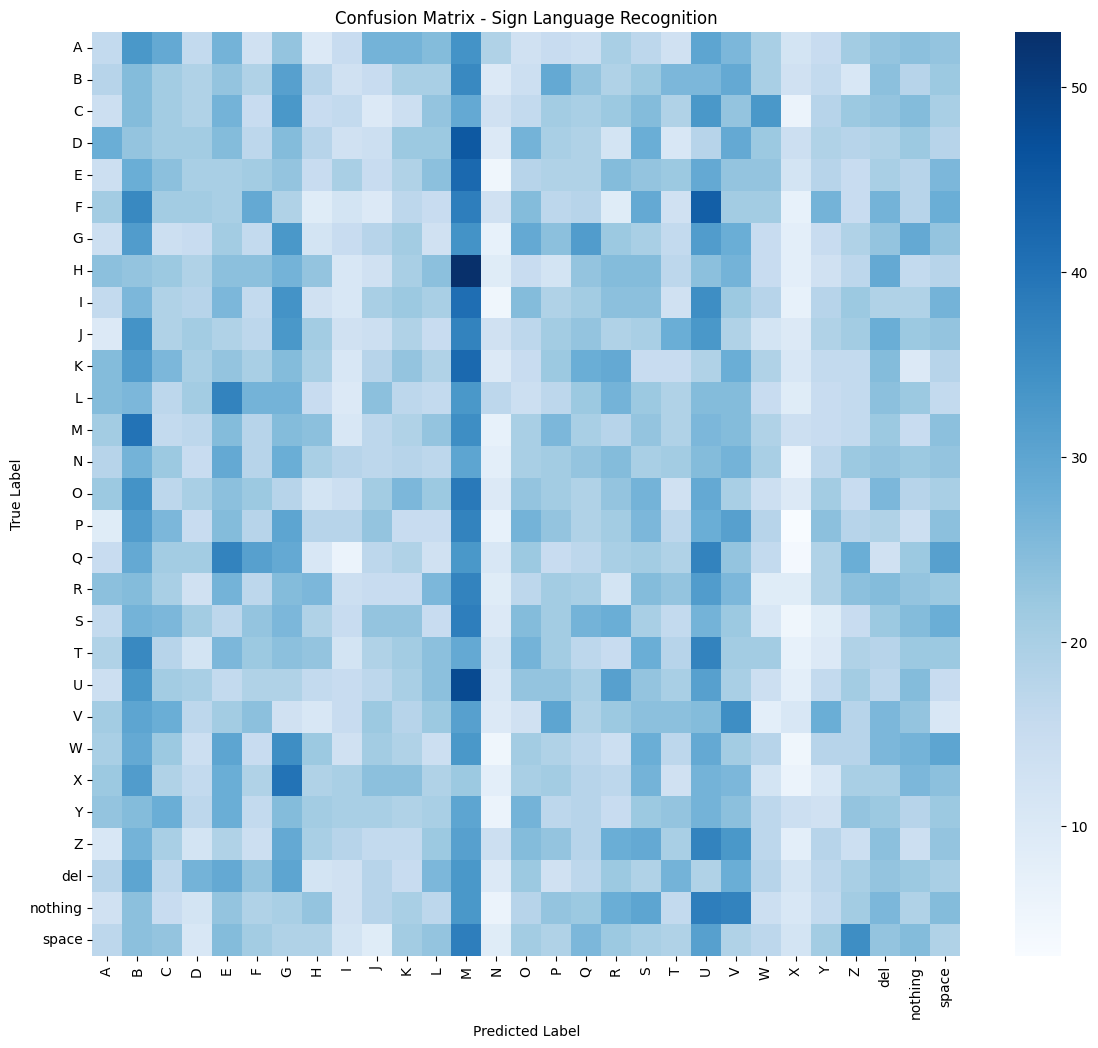

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get predictions
val_data.reset()

predictions = model.predict(val_data, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = val_data.classes

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Sign Language Recognition")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# 12. Classification Report

In [14]:
from sklearn.metrics import classification_report

report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names
)

print("Classification Report:\n")
print(report)

Classification Report:

              precision    recall  f1-score   support

           A       0.03      0.03      0.03       600
           B       0.03      0.04      0.03       600
           C       0.03      0.04      0.03       600
           D       0.04      0.04      0.04       600
           E       0.03      0.03      0.03       600
           F       0.05      0.05      0.05       600
           G       0.04      0.06      0.05       600
           H       0.05      0.04      0.04       600
           I       0.03      0.02      0.02       600
           J       0.03      0.02      0.03       600
           K       0.04      0.04      0.04       600
           L       0.03      0.03      0.03       600
           M       0.03      0.06      0.04       600
           N       0.03      0.01      0.02       600
           O       0.04      0.04      0.04       600
           P       0.04      0.04      0.04       600
           Q       0.03      0.03      0.03       600
   

# 13. Final Results

In [15]:
print("========================================")
print("   SIGN LANGUAGE RECOGNITION PROJECT")
print("========================================")

print("\nModel: CNN (Convolutional Neural Network)")
print("Number of Classes:", len(class_names))
print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Validation Loss:", round(loss, 4))

print("\nProject Status: Completed Successfully! ✅")

   SIGN LANGUAGE RECOGNITION PROJECT

Model: CNN (Convolutional Neural Network)
Number of Classes: 29
Validation Accuracy: 81.96 %
Validation Loss: 0.9731

Project Status: Completed Successfully! ✅


# 14. Conclusion


In [16]:
print("""
CONCLUSION

This project demonstrates the use of a Convolutional Neural Network (CNN)
for Sign Language Recognition.

The model was trained on 29 different sign classes including A-Z,
del, nothing, and space.

The trained CNN achieved a validation accuracy of 81.96%.

The project shows how Deep Learning and Computer Vision can be used
to recognize hand signs from images.

Future improvements can include:
- Using a larger and more diverse dataset
- Increasing image resolution
- Using data augmentation
- Using advanced CNN architectures
- Real-time sign language recognition using a camera
""")


CONCLUSION

This project demonstrates the use of a Convolutional Neural Network (CNN)
for Sign Language Recognition.

The model was trained on 29 different sign classes including A-Z,
del, nothing, and space.

The trained CNN achieved a validation accuracy of 81.96%.

The project shows how Deep Learning and Computer Vision can be used
to recognize hand signs from images.

Future improvements can include:
- Using a larger and more diverse dataset
- Increasing image resolution
- Using data augmentation
- Using advanced CNN architectures
- Real-time sign language recognition using a camera

